# Práctica Experimental 1 – Minería de Datos
## Predicción y segmentación de ventas de un mini market (datos simulados)

**Estudiante:** Marvin Alban · **Asignatura:** Minería de Datos (UEA-L-UFPTI-009)

> **Aviso:** el conjunto de datos es **simulado** (lo genera `src/generar_datos.py` con semilla fija). No proviene de un negocio real, de modo que los patrones que se "descubren" reflejan los supuestos del simulador. La finalidad es didáctica: practicar el proceso completo de minería de datos.

**Fases (DIKW):** Datos → Información (EDA) → Conocimiento (modelos) → Sabiduría (decisiones y despliegue).

In [1]:
import sys, os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score
import joblib

sys.path.append("../src")
from features import agregar_variables, NUM_COLS, CAT_COLS, FEATURES, TARGET

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", font_scale=0.9)
SEED = 42
DATA, FIG, RES, MOD = "../data/ventas_minimarket_simulado.csv", "../figuras", "../resultados", "../modelo"
for d in (FIG, RES, MOD):
    os.makedirs(d, exist_ok=True)
print("Librerías cargadas correctamente")

Librerías cargadas correctamente


## 1. Datos: carga y descripción
**Fuente:** conjunto simulado generado con `src/generar_datos.py` (semilla 2025). Cada fila es un *ticket* de venta del año 2025.

In [2]:
df_raw = pd.read_csv(DATA)
print("Dimensiones (filas, columnas):", df_raw.shape)
print("\nTipos de dato:")
print(df_raw.dtypes)
df_raw.head()

Dimensiones (filas, columnas): (5060, 10)

Tipos de dato:
id_ticket                  str
fecha                      str
dia_semana                 str
hora                   float64
categoria_principal        str
num_items              float64
metodo_pago                str
tipo_cliente               str
promocion                int64
monto_total            float64
dtype: object


## 2. Exploración de datos (EDA)

In [3]:
desc = df_raw.describe().T.round(2)
print("Estadísticas descriptivas (variables numéricas):")
print(desc)
desc.to_csv(f"{RES}/estadisticas_descriptivas.csv")

nulos = pd.DataFrame({"nulos": df_raw.isna().sum(),
                      "porcentaje": (df_raw.isna().mean() * 100).round(2)})
print("\nValores nulos por variable:")
print(nulos)
nulos.to_csv(f"{RES}/nulos.csv")

n_dup = int(df_raw.duplicated().sum())
pct_dup = round(n_dup / len(df_raw) * 100, 2)
print(f"\nRegistros duplicados (filas idénticas): {n_dup} ({pct_dup} %)")

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (s < lo) | (s > hi)
    return {"q1": q1, "q3": q3, "limite_inf": lo, "limite_sup": hi,
            "n_atipicos": int(mask.sum()), "pct": round(mask.mean() * 100, 2)}

atip = pd.DataFrame({c: iqr_outliers(df_raw[c].dropna()) for c in ["monto_total", "num_items"]}).T.round(2)
print("\nValores atípicos (regla del IQR):")
print(atip)
atip.to_csv(f"{RES}/atipicos.csv")
json.dump({"n_filas": len(df_raw), "n_columnas": df_raw.shape[1], "n_duplicados": n_dup, "pct_duplicados": pct_dup},
          open(f"{RES}/resumen_datos.json", "w"))

Estadísticas descriptivas (variables numéricas):
              count   mean    std   min    25%    50%    75%     max
hora         4999.0  14.51   3.90  7.00  11.00  15.00  18.00   21.00
num_items    5030.0   5.70   4.04  1.00   3.00   5.00   7.00   33.00
promocion    5060.0   0.21   0.41  0.00   0.00   0.00   0.00    1.00
monto_total  5060.0  12.81  15.51  0.37   5.01   8.96  15.62  562.89

Valores nulos por variable:
                     nulos  porcentaje
id_ticket                0        0.00
fecha                    0        0.00
dia_semana               0        0.00
hora                    61        1.21
categoria_principal      0        0.00
num_items               30        0.59
metodo_pago            125        2.47
tipo_cliente           153        3.02
promocion                0        0.00
monto_total              0        0.00

Registros duplicados (filas idénticas): 60 (1.19 %)

Valores atípicos (regla del IQR):
               q1     q3  limite_inf  limite_sup  n_atipicos

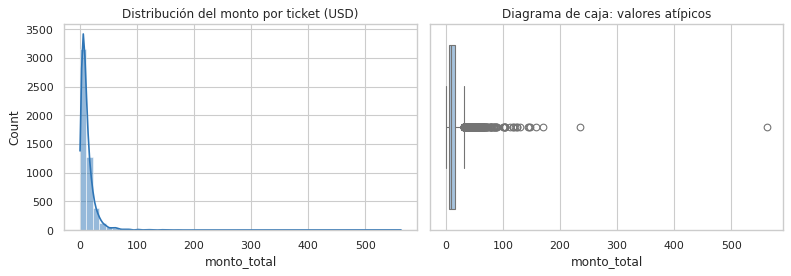

In [4]:
# Visualización 1: distribución del monto por ticket
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
sns.histplot(df_raw["monto_total"], bins=50, kde=True, ax=ax[0], color="#2E75B6")
ax[0].set_title("Distribución del monto por ticket (USD)"); ax[0].set_xlabel("monto_total")
sns.boxplot(x=df_raw["monto_total"], ax=ax[1], color="#9DC3E6")
ax[1].set_title("Diagrama de caja: valores atípicos"); ax[1].set_xlabel("monto_total")
plt.tight_layout(); plt.savefig(f"{FIG}/eda_1_distribucion_monto.png", dpi=110); plt.show()

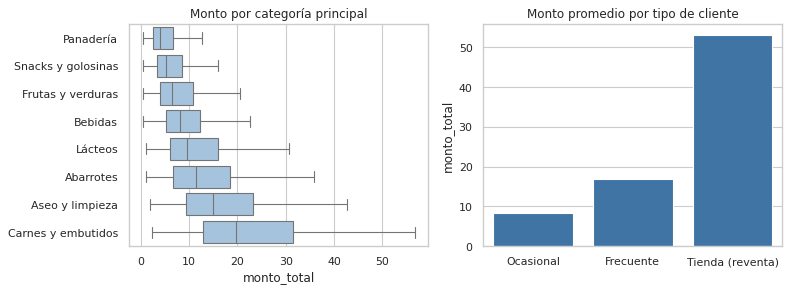

In [5]:
# Visualización 2: monto por categoría y por tipo de cliente
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
orden = df_raw.groupby("categoria_principal")["monto_total"].median().sort_values().index
sns.boxplot(data=df_raw, y="categoria_principal", x="monto_total", order=orden, ax=ax[0], color="#9DC3E6", showfliers=False)
ax[0].set_title("Monto por categoría principal"); ax[0].set_ylabel("")
sns.barplot(data=df_raw, x="tipo_cliente", y="monto_total", ax=ax[1], color="#2E75B6", errorbar=None)
ax[1].set_title("Monto promedio por tipo de cliente"); ax[1].set_xlabel("")
plt.tight_layout(); plt.savefig(f"{FIG}/eda_2_categoria_cliente.png", dpi=110); plt.show()

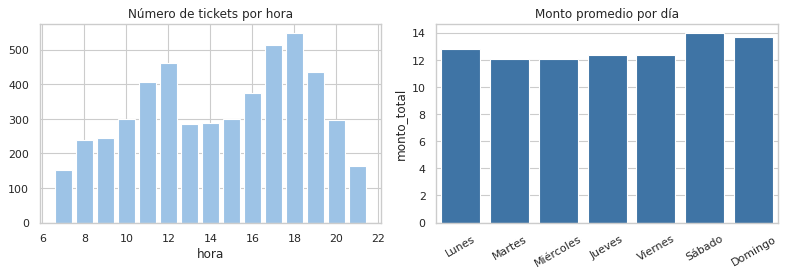

In [6]:
# Visualización 3: ventas por hora y día de la semana
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
por_hora = df_raw.groupby("hora")["monto_total"].agg(["count", "mean"]).reset_index()
ax[0].bar(por_hora["hora"], por_hora["count"], color="#9DC3E6")
ax[0].set_title("Número de tickets por hora"); ax[0].set_xlabel("hora")
dias = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
sns.barplot(data=df_raw, x="dia_semana", y="monto_total", order=dias, ax=ax[1], color="#2E75B6", errorbar=None)
ax[1].set_title("Monto promedio por día"); ax[1].set_xlabel(""); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{FIG}/eda_3_hora_dia.png", dpi=110); plt.show()

Correlación con monto_total:
monto_total         1.000
num_items           0.646
hora                0.028
promocion          -0.035
es_fin_de_semana    0.046
es_dia_de_pago      0.049
mes                 0.009
Name: monto_total, dtype: float64


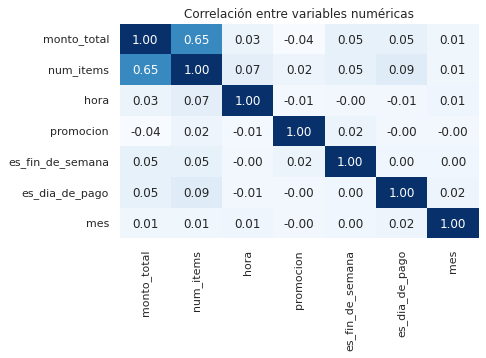

In [7]:
# Visualización 4: matriz de correlación (variables numéricas)
tmp = agregar_variables(df_raw)
cols = ["monto_total", "num_items", "hora", "promocion", "es_fin_de_semana", "es_dia_de_pago", "mes"]
plt.figure(figsize=(6.2, 4.6))
sns.heatmap(tmp[cols].corr(), annot=True, fmt=".2f", cmap="Blues", cbar=False)
plt.title("Correlación entre variables numéricas")
plt.tight_layout(); plt.savefig(f"{FIG}/eda_4_correlacion.png", dpi=110); plt.show()
print("Correlación con monto_total:")
print(tmp[cols].corr()["monto_total"].round(3))

## 3. Preprocesamiento
1. **Duplicados:** se eliminan las filas completamente idénticas.
2. **Nulos:** se imputan *dentro del pipeline* (solo con datos de entrenamiento, para evitar fuga de información): mediana en numéricas y categoría `"Desconocido"` en categóricas.
3. **Atípicos:** se **conservan** porque corresponden a compras especiales plausibles (eventos, reventa); se evalúan con modelos robustos y métrica MAE.
4. **Transformaciones:** estandarización (`StandardScaler`) de numéricas y codificación *one-hot* de categóricas.
5. **Feature engineering:** `franja_horaria`, `es_fin_de_semana`, `es_dia_de_pago`, `mes` y `dia_semana`, derivadas de `fecha` y `hora`.

In [8]:
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f"Filas antes: {len(df_raw)} | después de eliminar duplicados: {len(df)}")
df = agregar_variables(df)
print("\nVariables derivadas creadas: dia_semana, mes, es_fin_de_semana, es_dia_de_pago, franja_horaria")
print(df[["fecha", "hora", "franja_horaria", "es_fin_de_semana", "es_dia_de_pago", "mes"]].head())

X, y = df[FEATURES], df[TARGET]
preprocesador = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), NUM_COLS),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Desconocido")),
                      ("ohe", OneHotEncoder(handle_unknown="ignore"))]), CAT_COLS),
])
print("\nNulos restantes por columna de entrada (se imputan en el pipeline):")
print(X.isna().sum()[X.isna().sum() > 0])

Filas antes: 5060 | después de eliminar duplicados: 5000

Variables derivadas creadas: dia_semana, mes, es_fin_de_semana, es_dia_de_pago, franja_horaria
        fecha  hora franja_horaria  es_fin_de_semana  es_dia_de_pago  mes
0  2025-01-01  17.0          Tarde                 0               1    1
1  2025-01-01  12.0       Mediodía                 0               1    1
2  2025-01-01  21.0          Noche                 0               1    1
3  2025-01-01  10.0         Mañana                 0               1    1
4  2025-01-01  18.0          Tarde                 0               1    1

Nulos restantes por columna de entrada (se imputan en el pipeline):
hora             60
num_items        30
metodo_pago     120
tipo_cliente    150
dtype: int64


## 4. Modelado
Se comparan **tres técnicas de regresión**: regresión lineal (línea base interpretable), árbol de decisión y random forest. Partición **80 % entrenamiento / 20 % prueba** (`random_state=42`).

In [9]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, random_state=SEED)
print(f"Entrenamiento: {len(X_tr)} filas (80 %) | Prueba: {len(X_te)} filas (20 %)")

modelos = {
    "Regresión lineal": LinearRegression(),
    "Árbol de decisión": DecisionTreeRegressor(max_depth=6, min_samples_leaf=20, random_state=SEED),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=12, min_samples_leaf=5,
                                           random_state=SEED, n_jobs=-1),
}
parametros = {
    "Regresión lineal": "Mínimos cuadrados ordinarios (sin regularización)",
    "Árbol de decisión": "max_depth=6, min_samples_leaf=20, random_state=42",
    "Random Forest": "n_estimators=300, max_depth=12, min_samples_leaf=5, random_state=42",
}
for k, v in parametros.items():
    print(f"{k}: {v}")

Entrenamiento: 4000 filas (80 %) | Prueba: 1000 filas (20 %)
Regresión lineal: Mínimos cuadrados ordinarios (sin regularización)
Árbol de decisión: max_depth=6, min_samples_leaf=20, random_state=42
Random Forest: n_estimators=300, max_depth=12, min_samples_leaf=5, random_state=42


## 5. Evaluación y validación
Métricas: **MAE**, **RMSE** y **R²**. Validación cruzada de **5 particiones** (`KFold`, con mezcla) sobre el conjunto de entrenamiento y evaluación final en el conjunto de prueba.

In [10]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"}
filas, pipes, preds = [], {}, {}
for nombre, modelo in modelos.items():
    pipe = Pipeline([("prep", preprocesador), ("modelo", modelo)])
    cv = cross_validate(pipe, X_tr, y_tr, cv=kf, scoring=scoring)
    pipe.fit(X_tr, y_tr)
    pred = pipe.predict(X_te)
    pipes[nombre], preds[nombre] = pipe, pred
    filas.append({
        "Modelo": nombre,
        "CV MAE": -cv["test_mae"].mean(), "CV MAE sd": cv["test_mae"].std(),
        "CV RMSE": -cv["test_rmse"].mean(), "CV R2": cv["test_r2"].mean(), "CV R2 sd": cv["test_r2"].std(),
        "Test MAE": mean_absolute_error(y_te, pred),
        "Test RMSE": float(np.sqrt(mean_squared_error(y_te, pred))),
        "Test R2": r2_score(y_te, pred),
    })
tabla = pd.DataFrame(filas).round(3)
tabla.to_csv(f"{RES}/tabla_comparativa.csv", index=False)
print(tabla.to_string(index=False))
mejor = tabla.sort_values("CV RMSE").iloc[0]["Modelo"]
print("\nMejor modelo según RMSE en validación cruzada:", mejor)

           Modelo  CV MAE  CV MAE sd  CV RMSE  CV R2  CV R2 sd  Test MAE  Test RMSE  Test R2
 Regresión lineal   4.296      0.203    9.574  0.628     0.149     4.271      9.241    0.609
Árbol de decisión   4.362      0.199   10.662  0.533     0.120     4.062      9.467    0.590
    Random Forest   3.366      0.333    8.783  0.687     0.178     3.420      8.756    0.649

Mejor modelo según RMSE en validación cruzada: Random Forest


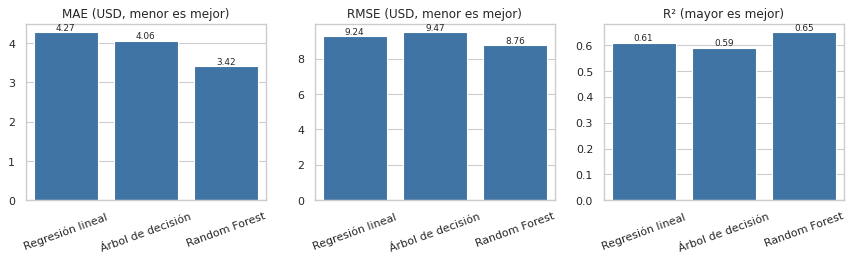

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.4))
for a, met, tit in zip(ax, ["Test MAE", "Test RMSE", "Test R2"], ["MAE (USD, menor es mejor)", "RMSE (USD, menor es mejor)", "R² (mayor es mejor)"]):
    sns.barplot(data=tabla, x="Modelo", y=met, ax=a, color="#2E75B6")
    a.set_title(tit); a.set_xlabel(""); a.set_ylabel(""); a.tick_params(axis="x", rotation=20)
    for p in a.patches:
        a.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/modelos_comparacion.png", dpi=110); plt.show()

Top 10 variables más importantes (Random Forest):
num__num_items                                 0.5773
cat__categoria_principal_Carnes y embutidos    0.1513
cat__categoria_principal_Aseo y limpieza       0.0911
cat__categoria_principal_Abarrotes             0.0353
cat__tipo_cliente_Tienda (reventa)             0.0306
num__hora                                      0.0247
num__mes                                       0.0148
cat__categoria_principal_Lácteos               0.0112
cat__dia_semana_Sábado                         0.0092
cat__categoria_principal_Snacks y golosinas    0.0071
dtype: float64


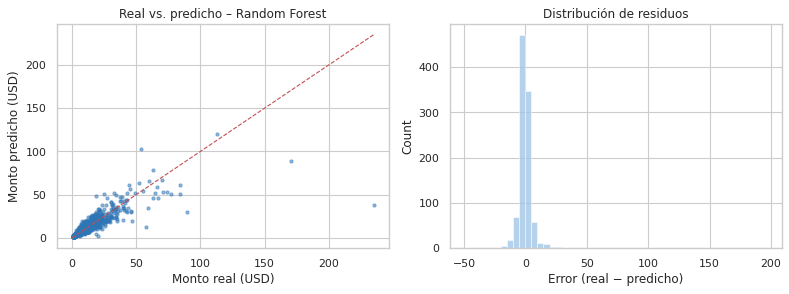

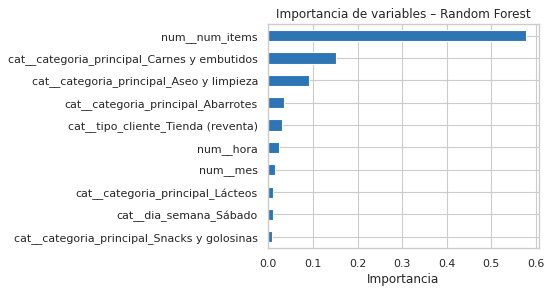

In [12]:
pred_mejor = preds[mejor]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].scatter(y_te, pred_mejor, s=8, alpha=0.5, color="#2E75B6")
lim = [0, max(y_te.max(), pred_mejor.max())]
ax[0].plot(lim, lim, "r--", lw=1); ax[0].set_xlabel("Monto real (USD)"); ax[0].set_ylabel("Monto predicho (USD)")
ax[0].set_title(f"Real vs. predicho – {mejor}")
sns.histplot(y_te - pred_mejor, bins=50, ax=ax[1], color="#9DC3E6")
ax[1].set_title("Distribución de residuos"); ax[1].set_xlabel("Error (real − predicho)")
plt.tight_layout(); plt.savefig(f"{FIG}/real_vs_predicho.png", dpi=110); plt.show()

# Importancia de variables (Random Forest)
rf = pipes["Random Forest"]
nombres = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["modelo"].feature_importances_, index=nombres).sort_values(ascending=False)
imp.round(4).to_csv(f"{RES}/importancia_variables.csv")
print("Top 10 variables más importantes (Random Forest):")
print(imp.head(10).round(4))
plt.figure(figsize=(7, 3.8))
imp.head(10).iloc[::-1].plot.barh(color="#2E75B6")
plt.title("Importancia de variables – Random Forest"); plt.xlabel("Importancia")
plt.tight_layout(); plt.savefig(f"{FIG}/importancia_variables.png", dpi=110); plt.show()

## 6. Técnica descriptiva adicional: segmentación con K-Means
Se agrupan los tickets según número de artículos, monto y hora para identificar perfiles de compra. El número de grupos se elige con el coeficiente de silueta.

Coeficiente de silueta por k: {2: 0.326, 3: 0.332, 4: 0.331, 5: 0.324, 6: 0.306}
k elegido: 3

Perfil de los segmentos:
          tickets  monto_prom  items_prom  hora_prom  pct_tienda
segmento                                                        
0            2038        7.52        4.05      17.56        0.00
1            1060       29.80       11.11      15.79       16.79
2            1902        9.00        4.43      10.60        0.00


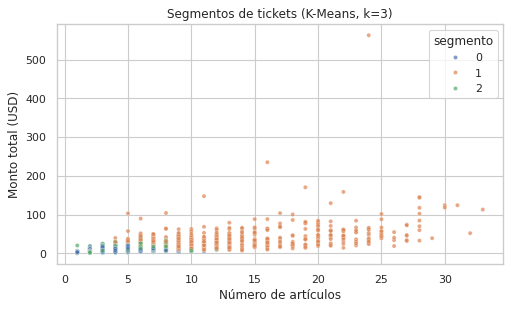

In [13]:
Xc = df[["num_items", "monto_total", "hora"]].copy()
Xc = Xc.fillna(Xc.median())
Xc_esc = StandardScaler().fit_transform(np.column_stack([Xc["num_items"], np.log1p(Xc["monto_total"]), Xc["hora"]]))
sil = {}
for k in range(2, 7):
    sil[k] = silhouette_score(Xc_esc, KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(Xc_esc))
print("Coeficiente de silueta por k:", {k: round(v, 3) for k, v in sil.items()})
k_opt = max(sil, key=sil.get)
print("k elegido:", k_opt)
km = KMeans(n_clusters=k_opt, n_init=10, random_state=SEED).fit(Xc_esc)
df["segmento"] = km.labels_
perfil = df.groupby("segmento").agg(tickets=("monto_total", "size"), monto_prom=("monto_total", "mean"),
                                    items_prom=("num_items", "mean"), hora_prom=("hora", "mean"),
                                    pct_tienda=("tipo_cliente", lambda s: (s == "Tienda (reventa)").mean() * 100)).round(2)
print("\nPerfil de los segmentos:")
print(perfil)
perfil.to_csv(f"{RES}/segmentos_kmeans.csv")
json.dump({"k": int(k_opt), "silueta": {str(k): float(v) for k, v in sil.items()}}, open(f"{RES}/kmeans_resumen.json", "w"))

plt.figure(figsize=(6.5, 4))
sns.scatterplot(data=df, x="num_items", y="monto_total", hue="segmento", palette="deep", s=14, alpha=0.7)
plt.title(f"Segmentos de tickets (K-Means, k={k_opt})"); plt.xlabel("Número de artículos"); plt.ylabel("Monto total (USD)")
plt.tight_layout(); plt.savefig(f"{FIG}/kmeans_segmentos.png", dpi=110); plt.show()

## 7. Extracción del modelo y prueba de uso
El modelo ganador se **reentrena con todos los datos limpios** y se guarda con `joblib` (incluye el preprocesamiento). Es el archivo que consume la API.

In [14]:
final = Pipeline([("prep", preprocesador), ("modelo", modelos[mejor])]).fit(X, y)
joblib.dump(final, f"{MOD}/modelo_monto.joblib")
meta = {
    "modelo": mejor, "features": FEATURES, "target": TARGET,
    "categorias": {c: sorted(df_raw[c].dropna().unique().tolist()) for c in ["categoria_principal", "metodo_pago", "tipo_cliente"]},
    "metricas_prueba": tabla.set_index("Modelo").loc[mejor, ["Test MAE", "Test RMSE", "Test R2"]].to_dict(),
    "nota": "Modelo entrenado con datos simulados; uso exclusivamente académico.",
}
json.dump(meta, open(f"{MOD}/metadatos.json", "w"), ensure_ascii=False, indent=2)

cargado = joblib.load(f"{MOD}/modelo_monto.joblib")
ejemplo = agregar_variables(pd.DataFrame([{
    "fecha": "2025-12-15", "hora": 18, "categoria_principal": "Abarrotes", "num_items": 8,
    "metodo_pago": "Tarjeta", "tipo_cliente": "Frecuente", "promocion": 0}]))
print("Modelo guardado:", mejor)
print(f"Predicción de ejemplo (8 artículos, abarrotes, tarjeta, 15-dic, 18 h): USD {cargado.predict(ejemplo[FEATURES])[0]:.2f}")

Modelo guardado: Random Forest
Predicción de ejemplo (8 artículos, abarrotes, tarjeta, 15-dic, 18 h): USD 21.00


## 8. Conclusiones del cuaderno
* El número de artículos es la variable que más explica el monto del ticket, seguida de la categoría principal y del tipo de cliente.
* Los modelos se comparan con las mismas particiones y métricas; la elección se basa en la validación cruzada.
* **Limitación:** al ser datos simulados, el rendimiento y los patrones dependen de las reglas del simulador y no deben generalizarse a un negocio real.